In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import PredefinedSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from config import SEED, DATA

X = pd.read_csv(DATA + "/train/X_train.txt", sep=r"\s+", header=None).values
y = np.loadtxt(DATA + "/train/y_train.txt", dtype=int)
groups = np.loadtxt(DATA + "/train/subject_train.txt", dtype=int)

folds_table = pd.read_csv("results/folds.csv", index_col="person")["fold"]
fold_of_window = folds_table.loc[groups].values
saved_folds = PredefinedSplit(fold_of_window)

print(X.shape, fold_of_window.shape, saved_folds.get_n_splits())

(7352, 561) (7352,) 7


In [2]:
train_rows = fold_of_window != 0
val_rows = fold_of_window == 0

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
model.fit(X[train_rows], y[train_rows])

lr = model[-1]
print(lr.classes_)
print(lr.coef_.shape, lr.intercept_.shape)
print(train_rows.sum(), val_rows.sum())

[1 2 3 4 5 6]
(6, 561) (6,)
6294 1058


In [3]:
scaler = model[0]
x = scaler.transform(X[val_rows])[0]

scores = lr.coef_ @ x + lr.intercept_
probs = np.exp(scores) / np.exp(scores).sum()

print("scores:     ", np.round(scores, 2))
print("by hand:    ", np.round(probs, 3))
print("sklearn:    ", np.round(model.predict_proba(X[val_rows][:1]), 3))
print("true label: ", y[val_rows][0])

scores:      [ -4.52 -13.01  -5.75   6.6   16.42   0.27]
by hand:     [0. 0. 0. 0. 1. 0.]
sklearn:     [[0. 0. 0. 0. 1. 0.]]
true label:  5


fold 0 macro-F1: 0.932
wrong windows: 62 of 1058
wrong but over 90% confident: 12


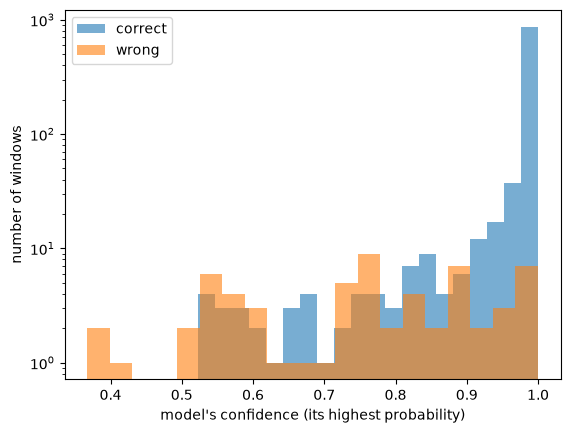

In [5]:
from sklearn.metrics import f1_score

P = model.predict_proba(X[val_rows])
pred = lr.classes_[P.argmax(axis=1)]
confidence = P.max(axis=1)
correct = pred == y[val_rows]

print("fold 0 macro-F1:", round(f1_score(y[val_rows], pred, average="macro"), 3))
print("wrong windows:", (~correct).sum(), "of", len(correct))
print("wrong but over 90% confident:", ((~correct) & (confidence > 0.9)).sum())

plt.hist(confidence[correct], bins=20, alpha=0.6, label="correct")
plt.hist(confidence[~correct], bins=20, alpha=0.6, label="wrong")
plt.xlabel("model's confidence (its highest probability)")
plt.ylabel("number of windows")
plt.legend()
plt.yscale("log")
plt.show()

In [ ]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
rows = []

for C in C_values:
    model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)) # logistic reg with ridge penalty
    f1s = cross_val_score(model, X, y, cv=saved_folds, scoring="f1_macro", n_jobs=-1)
    for fold in range(7):
        rows.append({"model": "logistic_L2", "setting": "C=" + str(C), "fold": fold, "macro_f1": f1s[fold]})
    print("C =", C, " mean", round(f1s.mean(), 3), " spread", round(f1s.std(), 3))

cv_l2 = pd.DataFrame(rows)

C = 0.001  mean 0.913  spread 0.033
C = 0.01  mean 0.928  spread 0.036
C = 0.1  mean 0.932  spread 0.035
C = 1  mean 0.933  spread 0.033
C = 10  mean 0.927  spread 0.031
C = 100  mean 0.922  spread 0.031


           mean     std      se
setting                        
C=0.001  0.9127  0.0358  0.0135
C=0.01   0.9278  0.0390  0.0147
C=0.1    0.9324  0.0383  0.0145
C=1      0.9330  0.0356  0.0135
C=10     0.9274  0.0340  0.0128
C=100    0.9218  0.0333  0.0126
best: C=1  threshold: 0.9196


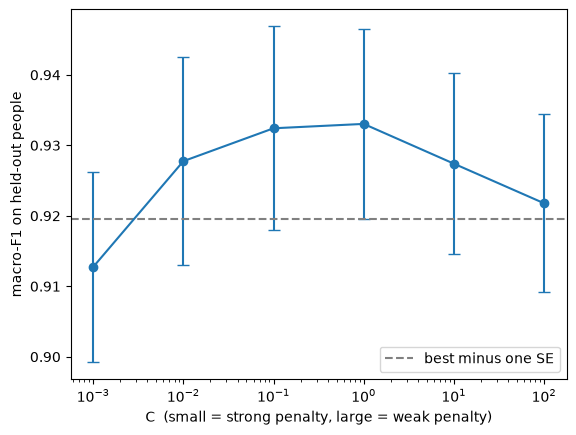

In [7]:
summary = cv_l2.groupby("setting", sort=False)["macro_f1"].agg(["mean", "std"])
summary["se"] = summary["std"] / np.sqrt(7)
print(summary.round(4))

best_setting = summary["mean"].idxmax()
threshold = summary.loc[best_setting, "mean"] - summary.loc[best_setting, "se"]
print("best:", best_setting, " threshold:", round(threshold, 4))

plt.errorbar(C_values, summary["mean"], yerr=summary["se"], marker="o", capsize=4)
plt.axhline(threshold, linestyle="--", color="grey", label="best minus one SE")
plt.xscale("log")
plt.xlabel("C  (small = strong penalty, large = weak penalty)")
plt.ylabel("macro-F1 on held-out people")
plt.legend()
plt.show()

In [9]:
from sklearn.model_selection import cross_validate

rows_l1 = []

for C in [0.01, 0.1, 1]:
    model = make_pipeline(StandardScaler(),
                             LogisticRegression(l1_ratio=1, solver="saga", C=C, max_iter=5000))
    out = cross_validate(model, X, y, cv=saved_folds, scoring="f1_macro",
                         return_estimator=True, n_jobs=-1)
    f1s = out["test_score"]
    kept = [int((est[-1].coef_ != 0).any(axis=0).sum()) for est in out["estimator"]]
    for fold in range(7):
        rows_l1.append({"model": "logistic_L1", "setting": "C=" + str(C), "fold": fold, "macro_f1": f1s[fold]})
    print("C =", C, " mean", round(f1s.mean(), 3), " spread", round(f1s.std(), 3), " kept per fold:", kept)

C = 0.01  mean 0.908  spread 0.036  kept per fold: [62, 71, 64, 73, 67, 67, 72]
C = 0.1  mean 0.934  spread 0.034  kept per fold: [190, 182, 177, 183, 161, 185, 185]
C = 1  mean 0.935  spread 0.032  kept per fold: [373, 388, 376, 389, 310, 369, 395]


In [10]:
cv_logistic = pd.concat([cv_l2, pd.DataFrame(rows_l1)], ignore_index=True)
cv_logistic.to_csv("results/cv_logistic.csv", index=False)

table = cv_logistic.groupby(["model", "setting"], sort=False)["macro_f1"].agg(["mean", "std"])
table["se"] = table["std"] / np.sqrt(7)
print(table.round(4))
print(len(cv_logistic), "rows saved")

                       mean     std      se
model       setting                        
logistic_L2 C=0.001  0.9127  0.0358  0.0135
            C=0.01   0.9278  0.0390  0.0147
            C=0.1    0.9324  0.0383  0.0145
            C=1      0.9330  0.0356  0.0135
            C=10     0.9274  0.0340  0.0128
            C=100    0.9218  0.0333  0.0126
logistic_L1 C=0.01   0.9081  0.0394  0.0149
            C=0.1    0.9341  0.0362  0.0137
            C=1      0.9353  0.0345  0.0130
63 rows saved


# Part 4 summary: logistic regression (ridge vs lasso)

**Data used:** the 21 training people only, with the saved person-wise folds (`results/folds.csv`). The 9 test people are untouched.
**Main metric:** macro-F1, averaged over the 7 folds. Baseline to beat: 0.05 (majority class).

## What the model computes (L06)
- Logistic regression gives each of the 6 activities a **score** = weighted sum of the 561 features + a bias: `s_k = w_k · x + b_k`.
- **Softmax** turns the 6 scores into probabilities that add up to 1: `p_k = e^(s_k) / Σ e^(s_j)`. The prediction is the activity with the highest probability.
- Learned numbers: 6 × 561 weights + 6 biases = **3,372**.
- **Fitting** = maximum likelihood = minimising the log-loss (−log of the probability given to the true activity), **plus a penalty** on big weights. The loss is convex, so there is one best answer.
- **Assumption:** the scores are *linear* in the features, so the boundaries between activities are flat (hyperplanes). The RBF SVM (Part 5) relaxes this.

## Cell by cell
**Cell 1: load.** X (7352 × 561), y, groups; the saved folds loaded with `PredefinedSplit`, so every model uses exactly the same 7 folds.

**Cell 2: fit one model.** Trained on 18 people (6,294 windows), with fold 0 held out (people 15, 22, 25; 1,058 windows). The pipeline is `StandardScaler` + `LogisticRegression`, so the scaling is learned from the training people only. `coef_` is 6 × 561.

**Cell 3: one prediction by hand.** For one window of person 15: scores = [−4.52, −13.01, −5.75, 6.60, **16.42**, 0.27] → predicted **standing** (correct). The runner-up was **sitting**, the physically similar posture. Our hand-computed softmax matched scikit-learn exactly, so the model is just "weighted sum → softmax → pick the biggest".

**Cell 4: confidence on fold 0.** Macro-F1 = **0.932** (the same as Module 3's fold 0, so the result is reproducible). 62 of 1,058 windows were wrong.
- Correct windows pile up at 99–100% confidence.
- Wrong windows are spread out between 0.4 and 1.0, and every window under 50% confidence was wrong.
- **But 12 of the 62 mistakes were over 90% confident**: the model can be confidently wrong. These are candidates for the error analysis (Part 8).

**Cells 5–6: ridge (L2), tuning C.** The penalty is `(1/C) × Σ w²`. **Small C = strong penalty.**

| C | 0.001 | 0.01 | 0.1 | 1 | 10 | 100 |
|---|---|---|---|---|---|---|
| macro-F1 | 0.913 | 0.928 | 0.932 | **0.933** | 0.927 | 0.922 |

- C too small → underfitting; C too large → slight overfitting. The curve is very **flat**: the differences between C values (about 0.006) are much smaller than the differences between folds (about 0.035). **Which people are in the fold matters more than C.**
- **One-standard-error rule:** SE = std ÷ √7 ≈ 0.0135, so the threshold is 0.933 − 0.0135 = 0.9196. Every C from 0.01 to 100 counts as "as good as the best", and the strongest penalty among them is **C = 0.01** (0.928).
- Caveat: every C is tested on the same folds, so this SE is cautious; a fold-by-fold comparison would be more sensitive.

**Cell 7: lasso (L1).** The penalty is `(1/C) × Σ |w|`. The sharp corner at 0 pushes many weights to **exactly 0**, so lasso drops features.

| C | Features kept (of 561, per fold) | macro-F1 |
|---|---|---|
| 0.01 | 62–73 | 0.908 |
| 0.1 | 161–190 | **0.934** |
| 1 | 310–395 | 0.935 |

- **About a third of the features is enough:** lasso at C = 0.1 matches ridge's best score with about 180 features instead of 561 (the features are highly redundant: 8,206 pairs with |r| > 0.9).
- The kept features **change from fold to fold**: with near-copy features, lasso picks one copy fairly arbitrarily. So we **don't treat lasso's chosen features as "the important ones"**.
- One-SE rule for lasso: threshold 0.935 − 0.013 = 0.922 → **C = 0.1**.
- Technical notes: in scikit-learn 1.8, lasso is set with `l1_ratio=1` (`penalty="l1"` is deprecated). Lasso needs the `saga` solver, which is slow (**about 24 minutes** for 21 fits on a laptop CPU) because the corner in |w| rules out the fast smooth solver. Ridge took seconds.

**Cell 8: saved** all 63 fold scores (42 ridge + 21 lasso) to `results/cv_logistic.csv` (columns: model, setting, fold, macro_f1).

## Decision carried to Part 7
- **Logistic regression candidate: lasso, C = 0.1** (macro-F1 0.934 ± 0.014 SE, about 180 features).
- Alternative: ridge, C = 0.01 (0.928). All logistic variants from C = 0.01 upwards are within noise of each other.

## Five takeaways
1. Logistic regression is transparent: weighted sum → softmax. We reproduced its output by hand.
2. Its confidence is informative but not fully trustworthy (about 1 in 5 errors happen at more than 90% confidence).
3. Regularisation strength barely matters here; person-to-person variation dominates.
4. Lasso shows that about a third of the 561 features is enough for the same score.
5. Lasso's specific feature choices are unstable, so we claim a *number* of features, not a list of important ones.